# Unit 1 — Menentukan Objektif Bisnis
**Kode unit:** J.62DMI00.001.1 · **Acuan:** SKKNI No. 299 Tahun 2020 (Ilmuwan Data) · **Proyek:** Prediksi Arah Harian IHSG

> Notebook ini menetapkan **mengapa** proyek dilakukan: latar belakang bisnis, pemangku kepentingan, tujuan bisnis, kriteria keberhasilan, serta risiko dan asumsi. Seluruh keputusan teknis pada notebook berikutnya diturunkan dari dokumen ini.

## 1. Latar belakang bisnis

IHSG (Indeks Harga Saham Gabungan) adalah barometer utama pasar saham Indonesia. Pergerakan hariannya dipengaruhi
faktor **domestik** (kurs rupiah, suku bunga Bank Indonesia) dan **global** (indeks S&P 500, indeks volatilitas VIX,
harga minyak, harga emas).

Ada satu fakta kelembagaan yang penting: **Bursa Efek Indonesia (BEI) tutup pukul 16.00 WIB, sedangkan bursa Amerika
Serikat baru berdagang pada malam harinya (±20.30–03.00 WIB).** Artinya, ketika BEI dibuka keesokan pagi, pelaku pasar
sudah mengetahui hasil sesi AS, harga komoditas, dan kurs terbaru.

**Pertanyaan bisnis:** *Apakah informasi pasar yang sudah tersedia sebelum BEI dibuka dapat membantu memperkirakan
apakah IHSG akan ditutup lebih tinggi pada hari bursa berikutnya?*

**Studi kasus (hipotetis):** tim riset sebuah perusahaan sekuritas/manajer investasi yang setiap pagi menerbitkan
*morning brief* untuk tim investasi dan nasabah.

## 2. Pemangku kepentingan

| Pemangku kepentingan | Peran | Kebutuhan terhadap proyek | Pengaruh | Kepentingan |
|---|---|---|---|---|
| Manajer investasi | Pengambil keputusan alokasi portofolio | Sinyal arah pasar harian beserta tingkat keyakinannya | Tinggi | Tinggi |
| Analis riset | Penyusun *morning brief* | Faktor global/domestik yang paling berpengaruh, mudah dijelaskan | Sedang | Tinggi |
| Manajemen risiko | Pengendali eksposur | Peringatan dini hari dengan peluang turun tinggi | Tinggi | Sedang |
| Kepatuhan (*compliance*) | Menjamin materi riset sesuai ketentuan | Disclaimer, keterlacakan sumber data dan metode | Tinggi | Rendah |
| Investor ritel | Penerima laporan riset | Informasi ringkas dan tidak menyesatkan | Rendah | Sedang |
| Tim data science | Pengembang dan pemelihara model | Data bersih, kriteria evaluasi yang jelas | Sedang | Tinggi |

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RAW = Path('../data/raw/market_data.csv')
PROC = Path('../data/processed')
FIG = Path('../figures')
REP = Path('../reports')
MOD = Path('../models')
for p in (PROC, FIG, REP, MOD):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EDA_END = '2022-12-31'
C_UP, C_DOWN, C_NAVY, C_ACCENT, C_GREY = '#1a9850', '#d73027', '#1f3a5f', '#e08214', '#8c8c8c'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold',
})

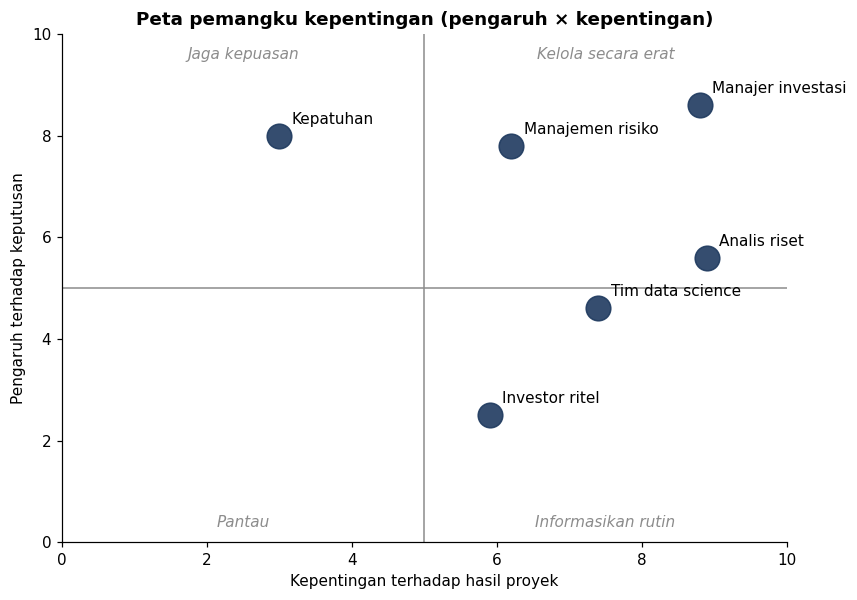

In [2]:
stakeholders = [
    # nama, pengaruh (0-10), kepentingan (0-10)
    ('Manajer investasi', 8.6, 8.8),
    ('Analis riset', 5.6, 8.9),
    ('Manajemen risiko', 7.8, 6.2),
    ('Kepatuhan', 8.0, 3.0),
    ('Investor ritel', 2.5, 5.9),
    ('Tim data science', 4.6, 7.4),
]
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.axhline(5, color=C_GREY, lw=1); ax.axvline(5, color=C_GREY, lw=1)
quadrants = {(2.5, 9.6): 'Jaga kepuasan', (7.5, 9.6): 'Kelola secara erat',
             (2.5, 0.4): 'Pantau', (7.5, 0.4): 'Informasikan rutin'}
for (x, y), label in quadrants.items():
    ax.text(x, y, label, ha='center', va='center', fontsize=10, color=C_GREY, style='italic')
for name, power, interest in stakeholders:
    ax.scatter(interest, power, s=260, color=C_NAVY, alpha=0.9, zorder=3)
    ax.annotate(name, (interest, power), xytext=(8, 8), textcoords='offset points', fontsize=10)
ax.set_xlim(0, 10); ax.set_ylim(0, 10)
ax.set_xlabel('Kepentingan terhadap hasil proyek'); ax.set_ylabel('Pengaruh terhadap keputusan')
ax.set_title('Peta pemangku kepentingan (pengaruh × kepentingan)')
ax.grid(False)
plt.savefig(FIG / '01_stakeholder_map.png')
plt.show()

## 3. Tujuan bisnis

1. **Indikator arah harian.** Menyediakan probabilitas IHSG ditutup naik pada hari bursa berikutnya, terbit sebelum
   pembukaan BEI (09.00 WIB), sebagai bahan *morning brief*.
2. **Faktor pendorong.** Mengidentifikasi variabel global/domestik yang paling berpengaruh terhadap arah IHSG
   keesokan hari sehingga analis dapat menjelaskannya kepada pengguna.
3. **Dukungan manajemen risiko.** Menandai hari dengan peluang turun yang tinggi sebagai peringatan dini.

**Di luar cakupan:** proyek ini *bukan* sistem *trading* otomatis dan *bukan* rekomendasi investasi.

## 4. Kriteria keberhasilan bisnis

| No | Kriteria | Cara mengukur (diturunkan di Unit 2) |
|---|---|---|
| B1 | Indikator lebih informatif daripada aturan naif (selalu "naik" atau tebakan acak) | Perbandingan dengan baseline pada data uji |
| B2 | Faktor pendorong dapat dijelaskan ke pengguna non-teknis | Peringkat kepentingan fitur + interpretasi ekonomi |
| B3 | Dapat dihasilkan otomatis setiap hari sebelum 08.30 WIB dari data publik | Fitur hanya memakai data penutupan hari sebelumnya |
| B4 | Tidak menyesatkan pengguna | Pelaporan jujur atas keterbatasan + disclaimer |

## 5. Risiko, asumsi, dan mitigasi

| Risiko / asumsi | Dampak | Mitigasi |
|---|---|---|
| Pasar relatif efisien → sinyal prediktif lemah | Akurasi tinggi tidak realistis | Target realistis dan wajib dibandingkan dengan baseline |
| Perubahan rezim pasar (COVID-19 2020, siklus suku bunga 2022–2024) | Kinerja turun di periode baru | Validasi temporal, analisis per tahun, rencana monitoring *drift* |
| Kebocoran informasi masa depan (*look-ahead bias*) | Hasil uji terlalu optimistis | Aturan *point-in-time*: fitur hanya dari data yang sudah terbit |
| Kualitas data publik (kutipan harga keliru) | Fitur menyimpang | Validasi (Unit 4) dan pembersihan terdokumentasi (Unit 6) |
| Hasil dipakai sebagai saran investasi | Risiko reputasi/kepatuhan | Disclaimer dan posisi model sebagai alat bantu analisis |

In [3]:
business_objective = {
    'proyek': 'Prediksi Arah Harian IHSG Berbasis Indikator Pasar Global dan Domestik',
    'analis': 'M. Syamsuddin Wisnubroto',
    'studi_kasus': 'Tim riset perusahaan sekuritas / manajer investasi (hipotetis)',
    'pertanyaan_bisnis': ('Apakah informasi pasar yang tersedia sebelum BEI dibuka dapat memperkirakan '
                          'apakah IHSG ditutup lebih tinggi pada hari bursa berikutnya?'),
    'pemangku_kepentingan': [s[0] for s in stakeholders],
    'tujuan_bisnis': [
        'Indikator probabilitas arah IHSG hari bursa berikutnya, terbit sebelum 09.00 WIB',
        'Peringkat faktor global/domestik yang paling berpengaruh',
        'Peringatan dini hari dengan peluang turun tinggi',
    ],
    'di_luar_cakupan': ['Sistem trading otomatis', 'Rekomendasi investasi'],
    'kriteria_sukses_bisnis': {
        'B1': 'Lebih informatif daripada aturan naif (selalu naik / acak)',
        'B2': 'Faktor pendorong dapat dijelaskan',
        'B3': 'Dapat dihasilkan otomatis sebelum 08.30 WIB dari data publik',
        'B4': 'Keterbatasan dilaporkan secara jujur',
    },
    'risiko_utama': ['Sinyal lemah (efisiensi pasar)', 'Perubahan rezim', 'Look-ahead bias',
                     'Kualitas data publik', 'Penyalahgunaan sebagai saran investasi'],
}
with open(REP / 'business_objective.json', 'w', encoding='utf-8') as f:
    json.dump(business_objective, f, ensure_ascii=False, indent=2)

print('Pertanyaan bisnis:', business_objective['pertanyaan_bisnis'])
print('\nTujuan bisnis:')
for i, t in enumerate(business_objective['tujuan_bisnis'], 1):
    print(f'  {i}. {t}')
print('\nKriteria sukses bisnis:')
for k, v in business_objective['kriteria_sukses_bisnis'].items():
    print(f'  {k}: {v}')
print('\nTersimpan ->', REP / 'business_objective.json')

Pertanyaan bisnis: Apakah informasi pasar yang tersedia sebelum BEI dibuka dapat memperkirakan apakah IHSG ditutup lebih tinggi pada hari bursa berikutnya?

Tujuan bisnis:
  1. Indikator probabilitas arah IHSG hari bursa berikutnya, terbit sebelum 09.00 WIB
  2. Peringkat faktor global/domestik yang paling berpengaruh
  3. Peringatan dini hari dengan peluang turun tinggi

Kriteria sukses bisnis:
  B1: Lebih informatif daripada aturan naif (selalu naik / acak)
  B2: Faktor pendorong dapat dijelaskan
  B3: Dapat dihasilkan otomatis sebelum 08.30 WIB dari data publik
  B4: Keterbatasan dilaporkan secara jujur

Tersimpan -> ../reports/business_objective.json


## Ringkasan Unit 1

- Masalah bisnis dirumuskan sebagai **dukungan keputusan harian** (bukan sistem trading).
- Enam pemangku kepentingan dipetakan beserta kebutuhannya.
- Empat kriteria keberhasilan bisnis (B1–B4) akan diterjemahkan menjadi metrik teknis terukur pada **Unit 2**.
- Dokumen tujuan bisnis disimpan sebagai `reports/business_objective.json` agar dapat dilacak pada tahap review (Unit 11).